# 05. Correlation, PCA and factor analysis

**The question this notebook answers:** many of our fields say nearly the same thing (loan amount and installment, credit limit and balance). Can a handful of underlying dimensions describe them, and can those dimensions be named in terms a credit officer would recognise?

**What the brief asks:**
1. Show a **Spearman correlation matrix** of the numeric fields and check **multicollinearity** (for example VIF). Use it to explain why dimension reduction makes sense.
2. Run **PCA** on the treated and standardised numeric fields: explained variance, the number of components with a stated reason, interpreted loadings, and how much the outlier treatment changed the leading components.
3. Run **factor analysis** in more depth: test suitability (**KMO and Bartlett**), choose the number of factors (parallel analysis or scree), pick and justify a **rotation**, **name each factor only from what its loadings support**, and compute factor scores. Explain when factor analysis is preferable to PCA for this problem.

**Terms used in this notebook**
- **Correlation:** how closely two fields move together, from -1 to +1. **Spearman** compares the *rankings* of values, so a few giant values cannot dominate it.
- **VIF (variance inflation factor):** how well one field can be predicted from *all the others* together. Under 5 is fine, 5 to 10 is a concern, above 10 is a problem.
- **PCA (principal component analysis):** rotates the data onto new axes (*components*) ordered by how much of the total variation each captures. A **loading** says how strongly a field contributes to a component.
- **Factor analysis (FA):** assumes a few hidden *factors* drive the fields, and that each field also carries noise of its own. It models only the variation that fields **share**.

In [1]:
import os, json
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

from credit_risk.factor_fields import FACTOR_FIELDS
from credit_risk.factor_tools import bartlett_sphericity, kmo, parallel_analysis
from credit_risk.factors import MIN_MEAN_LOADING, SIGNATURES, FactorModel
from credit_risk.io import FIT_CUTOFF

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

ds = pd.read_parquet("contract/analytical_dataset.parquet")      # the contract table: treated fields, scores, label
ds["issue_d"] = pd.to_datetime(ds.issue_d)
fit = ds[ds.issue_d <= FIT_CUTOFF]                               # everything is learned on the fit window
X = fit[FACTOR_FIELDS]
scaler = StandardScaler().fit(X)                                 # standardise: mean 0, spread 1, so no field dominates by scale
Z = scaler.transform(X)
spec = json.load(open("contract/data_spec.json"))
print(f"{len(fit):,} loans, {len(FACTOR_FIELDS)} treated numeric fields, missing values: {int(X.isna().sum().sum())}")

14,373 loans, 21 treated numeric fields, missing values: 0


## A first look: what PCA does, on two fields

`loan_amnt` and `installment` are almost the same information (the installment is the payment on the amount). Standardised, plotted against each other, they almost form a line.

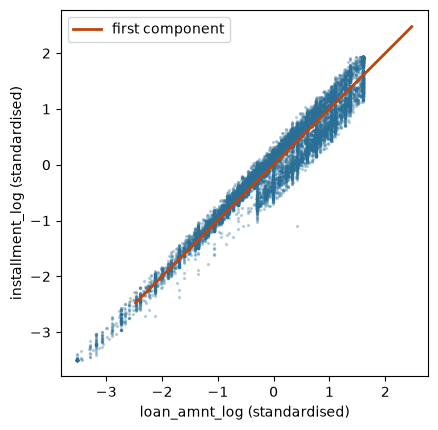

share of the total variation along each new axis: [0.988 0.012]
correlation of the two fields: 0.976


In [2]:
pair = StandardScaler().fit_transform(fit[["loan_amnt_log", "installment_log"]])
p2 = PCA().fit(pair)
fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.scatter(pair[:, 0], pair[:, 1], s=2, alpha=0.25, color="#2a6f97")
axis = p2.components_[0] * 3.5
ax.plot([-axis[0], axis[0]], [-axis[1], axis[1]], color="#c1440e", lw=2, label="first component")
ax.set_xlabel("loan_amnt_log (standardised)"); ax.set_ylabel("installment_log (standardised)"); ax.legend(); ax.set_aspect("equal")
fig.tight_layout(); plt.show()
print("share of the total variation along each new axis:", p2.explained_variance_ratio_.round(3))
print("correlation of the two fields:", round(float(np.corrcoef(pair.T)[0, 1]), 3))

**Reading it.** PCA finds the direction along which the data varies most (the red line) and makes it the first component. Here that single axis carries about 98% of the variation in both fields; the second axis, across the line, carries almost nothing. **Two fields became one component with almost no loss.** The same idea applied to 21 fields is what the rest of this notebook does.

## A second look: PCA versus factor analysis, on simulated data with a known answer

Real data never tells us the true structure, so we build a small case where we do know it: two hidden drivers (call them *a* and *b*), three fields driven by each, plus one field that is pure noise.

In [3]:
rng = np.random.default_rng(0)
n = 3000
a, b = rng.standard_normal(n), rng.standard_normal(n)
toy = pd.DataFrame({
    "x1 (driven by a)": a + 0.5 * rng.standard_normal(n), "x2 (driven by a)": a + 0.5 * rng.standard_normal(n), "x3 (driven by a)": a + 0.5 * rng.standard_normal(n),
    "x4 (driven by b)": b + 0.5 * rng.standard_normal(n), "x5 (driven by b)": b + 0.5 * rng.standard_normal(n), "x6 (driven by b)": b + 0.5 * rng.standard_normal(n),
    "x7 (pure noise)": rng.standard_normal(n)})
tz = StandardScaler().fit_transform(toy)
fa = FactorAnalysis(n_components=2, rotation="varimax", random_state=0).fit(tz)
loads = pd.DataFrame(fa.components_.T, index=toy.columns, columns=["factor 1", "factor 2"])
loads["communality (share of the field the factors explain)"] = (loads ** 2).sum(axis=1)
print(loads.round(2).to_string())
print("\nPCA on the same data, share of variation per component:", PCA().fit(tz).explained_variance_ratio_.round(2))

                  factor 1  factor 2  communality (share of the field the factors explain)
x1 (driven by a)     -0.90     -0.00                                                  0.80
x2 (driven by a)     -0.89     -0.01                                                  0.80
x3 (driven by a)     -0.89      0.01                                                  0.79
x4 (driven by b)      0.00     -0.89                                                  0.80
x5 (driven by b)     -0.00     -0.89                                                  0.80
x6 (driven by b)     -0.00     -0.89                                                  0.79
x7 (pure noise)       0.00     -0.03                                                  0.00

PCA on the same data, share of variation per component: [0.37 0.37 0.14 0.03 0.03 0.03 0.03]


**Reading it.** Factor analysis recovers the hidden structure: factor 1 is the three *a* fields, factor 2 the three *b* fields, and the noise field loads on neither. Its **communality** (the share of a field the factors explain) is close to zero, which is factor analysis saying "this field shares nothing with the others". PCA, by contrast, has no such concept: it reports seven components and simply gives the noise field a component of its own, because PCA summarises *all* variation, shared or not (its third component, 14% of the variation, is the noise field on its own). This difference is the answer to "when to prefer FA", discussed in section 5.

## 1. Correlation and multicollinearity (bullet 1)

Spearman correlation between all 21 treated fields, then the pairs that overlap most.

             field A                     field B  spearman
       loan_amnt_log             installment_log     0.966
     avg_cur_bal_log         tot_hi_cred_lim_log     0.902
      pub_rec_capped pub_rec_bankruptcies_capped     0.861
  revol_util_treated             bc_util_treated     0.803
       revol_bal_log        total_rev_hi_lim_log     0.795
acc_open_past_24mths          num_tl_op_past_12m     0.707
            open_acc                   total_acc     0.667
 tot_hi_cred_lim_log             mort_acc_capped     0.648

210 pairs in total: 6 at 0.7 or above, 5% at 0.5 or above, 20% at 0.3 or above


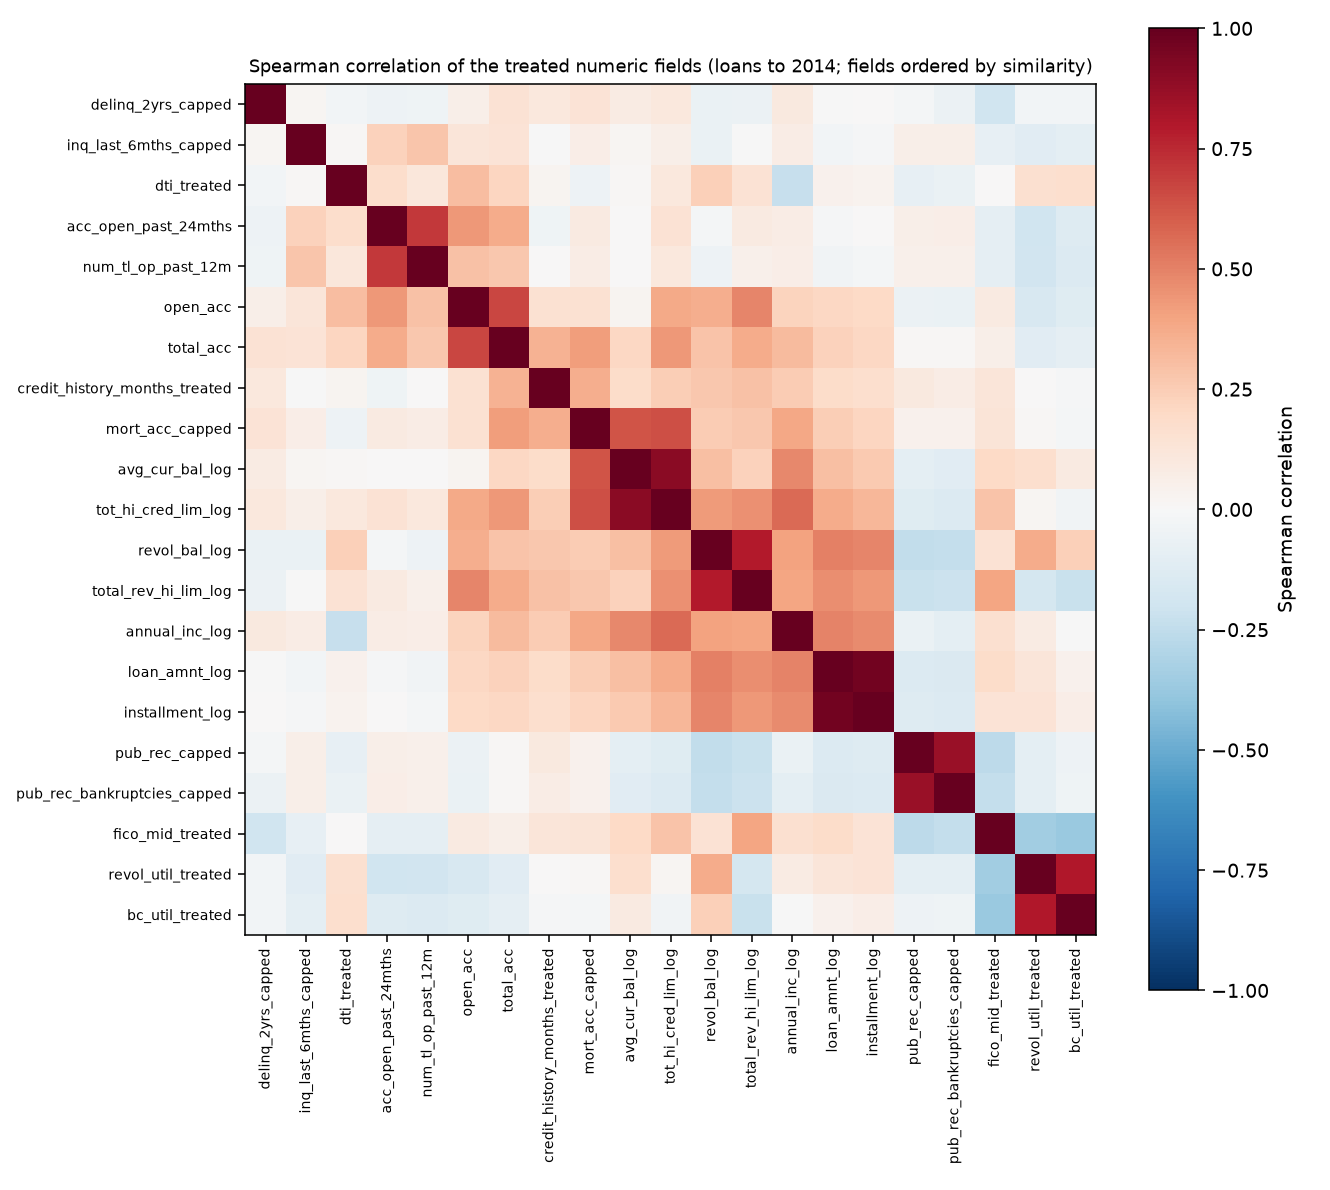

In [4]:
sp = fit[FACTOR_FIELDS].corr(method="spearman")
pairs = [(sp.index[i], sp.columns[j], sp.iloc[i, j]) for i in range(len(sp)) for j in range(i + 1, len(sp))]
pairs = pd.DataFrame(pairs, columns=["field A", "field B", "spearman"]).assign(abs_r=lambda d: d.spearman.abs()).sort_values("abs_r", ascending=False)
print(pairs.head(8).drop(columns="abs_r").round(3).to_string(index=False))
print(f"\n{len(pairs)} pairs in total: {(pairs.abs_r >= 0.7).sum()} at 0.7 or above, {(pairs.abs_r >= 0.5).mean():.0%} at 0.5 or above, {(pairs.abs_r >= 0.3).mean():.0%} at 0.3 or above")
display(Image("reports/a5_correlation_vif/figures/spearman_correlation.png", width=760))

In [5]:
Zc = np.column_stack([np.ones(len(Z)), Z])
vif = pd.Series([variance_inflation_factor(Zc, i + 1) for i in range(Z.shape[1])], index=FACTOR_FIELDS).sort_values(ascending=False)
print(vif.round(1).head(10).to_string())
print(f"\n{(vif > 5).sum()} of {len(vif)} fields have VIF above 5, and {(vif > 10).sum()} above 10")

loan_amnt_log                  23.1
tot_hi_cred_lim_log            22.6
installment_log                22.4
avg_cur_bal_log                17.6
total_rev_hi_lim_log           11.3
revol_bal_log                  11.2
revol_util_treated              6.3
open_acc                        4.3
bc_util_treated                 3.3
pub_rec_bankruptcies_capped     2.7

7 of 21 fields have VIF above 5, and 6 above 10


**Reading it.**
- **The matrix shows blocks of fields that repeat each other:** loan amount and installment (0.97), average balance and total credit limit (0.90), public records and bankruptcies (0.86), revolving and bank-card utilisation (0.80), revolving balance and limit (0.80), accounts opened in 12 and in 24 months (0.71).
- **VIF confirms it is serious:** several fields have a VIF above 10 (loan amount, credit limit, installment, average balance, revolving limit and balance), meaning each can be rebuilt almost exactly from the others. In a regression their coefficients would be unstable and uninterpretable.
- **Not everything overlaps:** `dti`, `delinq_2yrs` and `inq_last_6mths` are nearly independent of the rest.

**Why reduce dimensions.** A handful of underlying dimensions describes most of the 21 fields (credit size, loan size, utilisation, and so on). Replacing overlapping fields by a few independent scores removes the multicollinearity and gives the credit team fewer, more meaningful things to look at.

## 2. PCA on the treated, standardised fields (bullet 2)

**Standardised** means each field is rescaled to mean 0 and spread 1. Without it, a field measured in big numbers would dominate for no reason other than its units:

In [6]:
raw = PCA().fit(X.to_numpy())
dominant = X.columns[np.abs(raw.components_[0]).argmax()]
print(f"WITHOUT standardising: component 1 explains {raw.explained_variance_ratio_[0]:.0%} of the variance, and it is {np.abs(raw.components_[0]).max():.1%} the single field '{dominant}'")
print("   (that field is measured in months, so it has the largest numbers and takes over)")

WITHOUT standardising: component 1 explains 77% of the variance, and it is 99.8% the single field 'credit_history_months_treated'
   (that field is measured in months, so it has the largest numbers and takes over)


That is the "raw-scale PCA" failure the brief warns about, so every PCA here is on standardised fields. Now the real one:

    eigenvalue  share of variance  cumulative
1        4.779              0.228       0.228
2        2.794              0.133       0.361
3        2.196              0.105       0.465
4        1.921              0.091       0.557
5        1.527              0.073       0.629
6        1.319              0.063       0.692
7        1.137              0.054       0.746
8        0.896              0.043       0.789
9        0.839              0.040       0.829
10       0.750              0.036       0.865


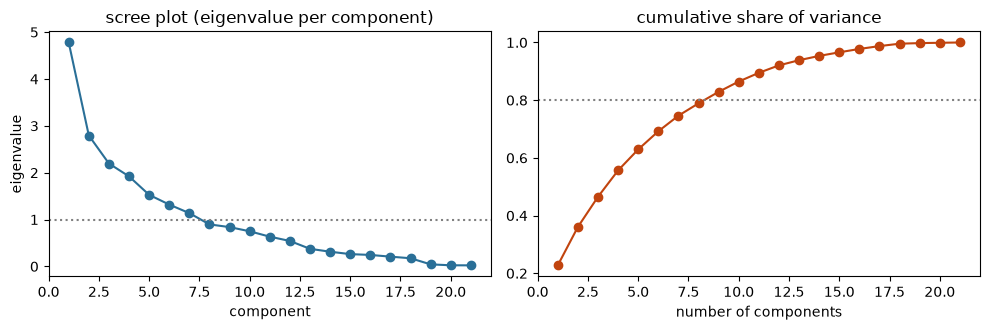

                                  rule  components
           Kaiser (eigenvalue above 1)           7
Parallel analysis (above 95% of noise)           7
      Cumulative variance at least 80%           9
      Cumulative variance at least 70%           7


In [7]:
pca = PCA().fit(Z)
ev = pca.explained_variance_
table = pd.DataFrame({"eigenvalue": ev, "share of variance": pca.explained_variance_ratio_, "cumulative": pca.explained_variance_ratio_.cumsum()},
                     index=range(1, len(ev) + 1))
print(table.head(10).round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(range(1, len(ev) + 1), ev, "o-", color="#2a6f97"); ax[0].axhline(1, color="grey", ls=":"); ax[0].set_title("scree plot (eigenvalue per component)")
ax[0].set_xlabel("component"); ax[0].set_ylabel("eigenvalue")
ax[1].plot(range(1, len(ev) + 1), pca.explained_variance_ratio_.cumsum(), "o-", color="#c1440e"); ax[1].axhline(0.8, color="grey", ls=":"); ax[1].set_title("cumulative share of variance")
ax[1].set_xlabel("number of components"); fig.tight_layout(); plt.show()
print(pd.read_csv("reports/a5_pca/tables/number_of_components_rules.csv").to_string(index=False))

**How many components, and why.** An **eigenvalue** is the amount of variation a component carries, measured in units of one standardised field. Three rules:
- **Kaiser:** keep components with eigenvalue above 1 (they carry more than one field's worth). Gives **7**.
- **Parallel analysis:** keep components whose eigenvalue beats the 95th percentile of the same eigenvalue from pure random noise. Also **7**.
- **Share of variance:** 70% needs 7 components (the same answer), while 80% would need 9, but components 8 and 9 do not beat noise.

**Choice: 7 components**, which carry about 75% of the variance. Two independent rules agree, and the extra ones would only describe noise.

### What the components mean (loadings)
A loading is how strongly a field contributes to a component; large positive or negative values name the component.

pc_1  (22.8% of variance): tot_hi_cred_lim_log +0.81, total_rev_hi_lim_log +0.74, annual_inc_log +0.68
pc_2  (13.3% of variance): revol_util_treated +0.77, bc_util_treated +0.69, acc_open_past_24mths -0.62
pc_3  (10.4% of variance): fico_mid_treated +0.72, bc_util_treated -0.59, revol_util_treated -0.52
pc_4  (9.2% of variance): pub_rec_capped +0.67, pub_rec_bankruptcies_capped +0.65, mort_acc_capped +0.45
pc_5  (7.3% of variance): installment_log +0.53, loan_amnt_log +0.51, avg_cur_bal_log -0.47
pc_6  (6.3% of variance): credit_history_months_treated +0.45, dti_treated +0.40, inq_last_6mths_capped -0.37
pc_7  (5.4% of variance): delinq_2yrs_capped +0.80, avg_cur_bal_log -0.30, credit_history_months_treated +0.26


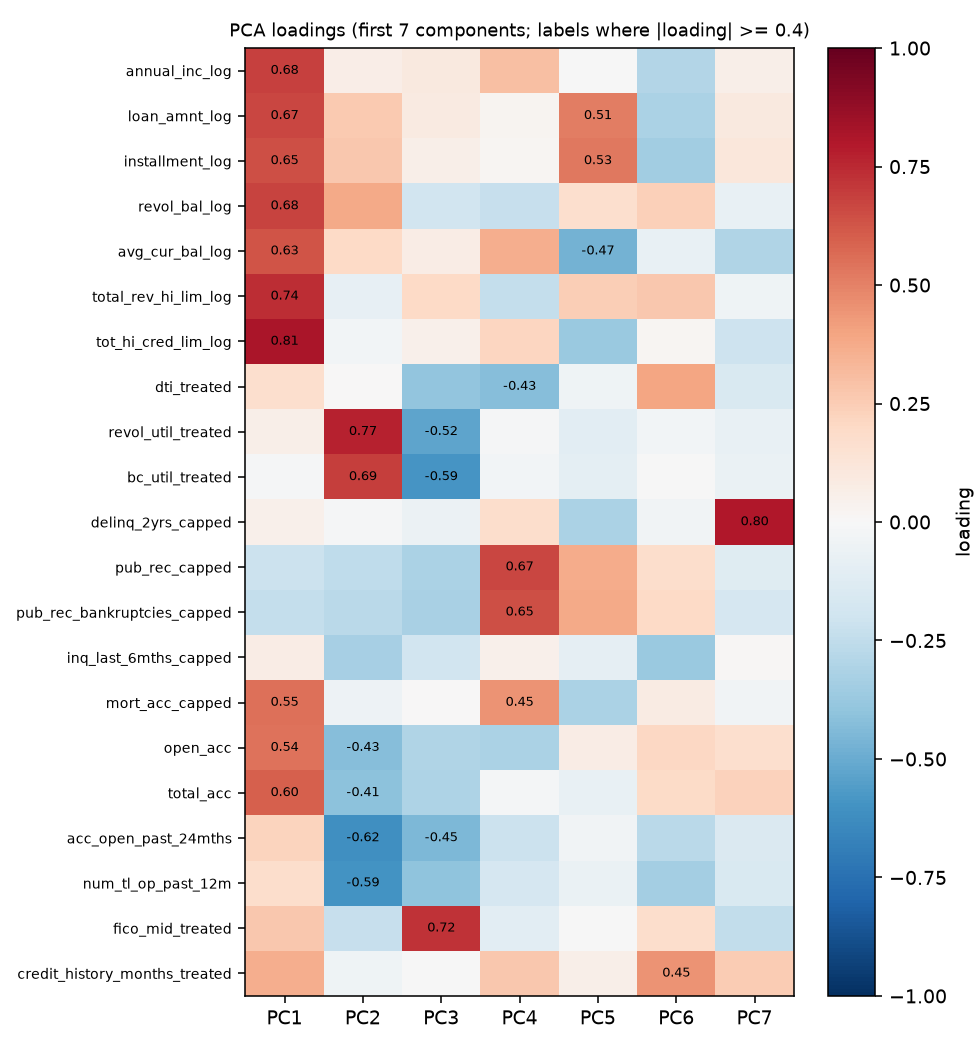

In [8]:
for c in spec["pca"]:
    top = ", ".join(f"{f} {v:+.2f}" for f, v in c["top_loadings"].items())
    print(f"{c['name']}  ({c['variance_explained']:.1%} of variance): {top}")
display(Image("reports/a5_pca/figures/pca_loadings.png", width=760))

**Reading it.** PC1 is overall *credit size* (total credit limit, revolving limit, income, revolving balance all rise together). PC2 sets *utilisation* against *recent account opening*. PC3 is the *FICO score* against utilisation. PC4 is *public records*. PC5 is *loan size*. PC6 is *credit history length and `dti`* against inquiries. PC7 is *delinquencies*. A component is a mathematical axis, so it can mix fields; naming is more reliable for factors (section 3).

### How much did the outlier treatment change the leading components?
We repeat the PCA on the same fields **without** the cap-and-log treatment from notebook 02 and compare.

In [9]:
print(pd.read_csv("reports/a5_pca/tables/outlier_treatment_effect.csv").round(3).head(3).to_string(index=False))
print()
print(pd.read_csv("reports/a5_pca/tables/treated_vs_untreated_summary.csv").to_string(index=False))

component  variance_share_treated  variance_share_untreated  loading_similarity (1 = identical)  score_rank_correlation  score_kurtosis_treated  score_kurtosis_untreated  largest_single_score_in_std_units_treated  largest_single_score_in_std_units_untreated
      PC1                   0.228                     0.201                               0.991                   0.978                  -0.218                     6.334                                      3.584                                       11.510
      PC2                   0.133                     0.130                               0.976                   0.969                   0.480                     1.072                                      7.254                                        7.977
      PC3                   0.105                     0.103                               0.958                   0.950                   1.054                     1.054                                      4.330              

**Reading it.** The structure is almost the same (loading similarity 0.99, 0.98, 0.96 for the first three components). What changes is the *behaviour of the scores*: untreated, PC1 explains 20% instead of 23%, its scores are heavy-tailed (kurtosis 6.3 against -0.2 treated), and a single loan sits 11.5 standard deviations from the centre against 3.6 after treatment. **The treatment mostly stops a few extreme loans from steering the leading component.**

## 3. Factor analysis (bullet 3)

### 3a. Is the data suitable?
Two standard checks before factoring anything:
- **Bartlett's test** asks whether the correlation matrix could be just noise (no shared structure at all). A tiny p-value says the fields do share structure.
- **KMO** (Kaiser-Meyer-Olkin) measures how much of each correlation is *shared* rather than pairwise coincidence. Above about 0.6 is the usual minimum; below 0.5 is unsuitable.

In [10]:
chi, p = bartlett_sphericity(Z)
per_field, overall = kmo(Z)
print(f"Bartlett chi-square = {chi:,.0f}, p-value = {p:.1e}")
print(f"KMO overall = {overall:.3f}\n")
k = pd.Series(per_field, index=FACTOR_FIELDS).sort_values()
print("fields with KMO below 0.6 (they share less with the others):")
print(k[k < 0.6].round(2).to_string())

Bartlett chi-square = 225,269, p-value = 0.0e+00
KMO overall = 0.661

fields with KMO below 0.6 (they share less with the others):
delinq_2yrs_capped             0.43
avg_cur_bal_log                0.56
dti_treated                    0.56
revol_util_treated             0.57
open_acc                       0.58
pub_rec_capped                 0.58
pub_rec_bankruptcies_capped    0.59


**Reading it.** Bartlett rejects "no shared structure" overwhelmingly, and the overall KMO of 0.66 clears the 0.6 minimum, so the data **is suitable** (middling, not excellent). Seven fields fall below 0.6, led by `delinq_2yrs` (0.43): these share little with the rest, so we should expect them to be poorly represented by any factor, and we check that later.

### 3b. How many factors?

parallel analysis keeps 10 factors (observed eigenvalue above 95% of random noise)
    observed  noise 95th percentile
1       4.58                   0.08
2       2.50                   0.07
3       1.82                   0.06
4       1.57                   0.05
5       1.36                   0.04
6       0.97                   0.04
7       0.57                   0.03
8       0.47                   0.02
9       0.22                   0.02
10      0.18                   0.01
11      0.00                   0.01
12     -0.01                   0.00

 factors  min_salient_loadings_per_factor  min_variance_share  total_variance  min_congruence_2013_vs_2014  passes_rule
       4                                3               0.096           0.449                        0.712        False
       5                                2               0.084           0.542                        0.978         True
       6                                2               0.080           0.597           

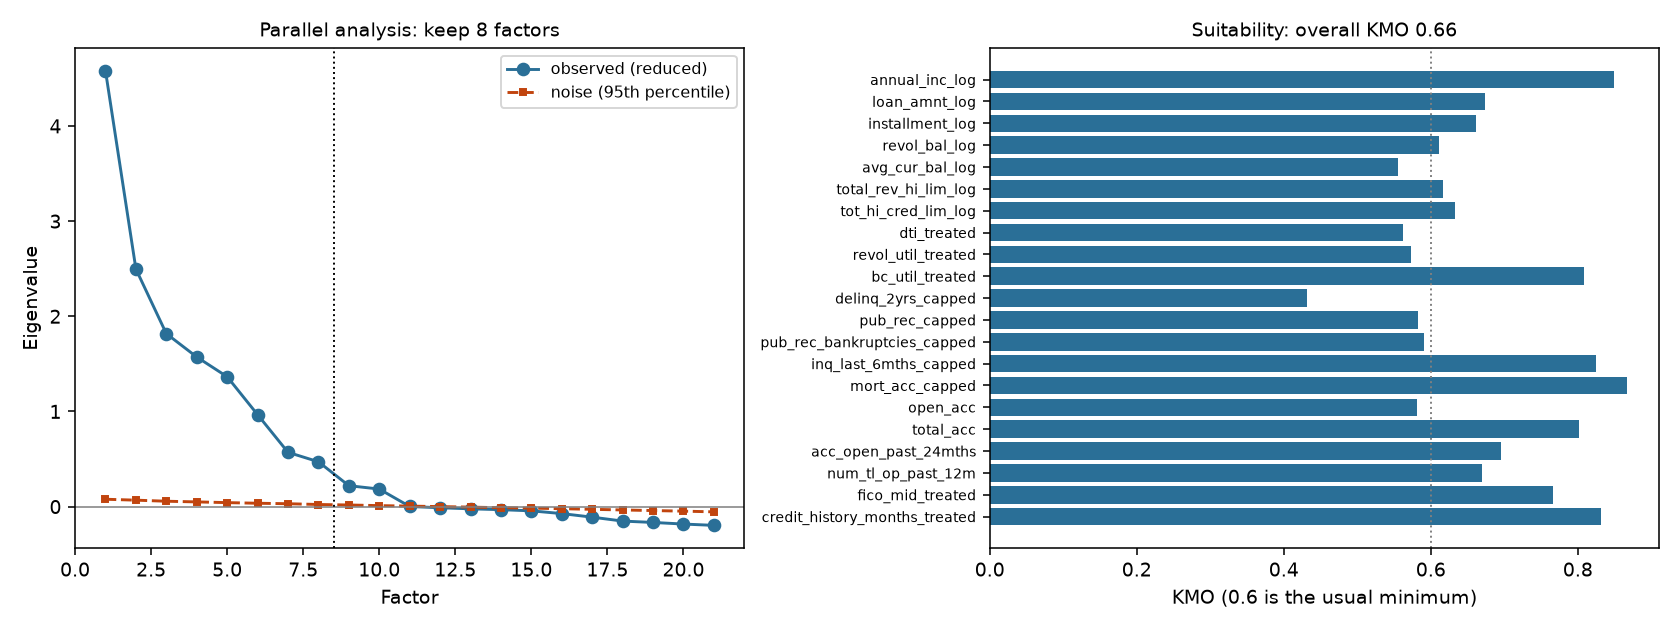

In [11]:
keep, observed, noise = parallel_analysis(Z)
print(f"parallel analysis keeps {keep} factors (observed eigenvalue above 95% of random noise)")
print(pd.DataFrame({"observed": observed[:12], "noise 95th percentile": noise[:12]}, index=range(1, 13)).round(2).to_string())
print()
print(pd.read_csv("reports/a5_factor_analysis/tables/number_of_factors_rule.csv").to_string(index=False))
display(Image("reports/a5_factor_analysis/figures/parallel_analysis_and_kmo.png", width=900))

**Reading it.** Parallel analysis alone says **10**, but with 14,000 loans almost any real pattern beats noise, so it overstates. We therefore used a **stricter rule, fixed before looking at the result**: the largest number of factors in which every factor (a) has at least two loadings of 0.4 or more, (b) explains at least 3% of the variance, and (c) is stable between 2013 and 2014 (congruence at least 0.95). Five to eight factors pass; nine fails (a factor with only 2.4% of the variance) and ten fails (a factor with a single clear loading). **We use 8.** The PCA gives 7, so the factor solution has one more dimension, and the eighth (`dti` against income) is the one that gives `dti` a home.

### 3c. Rotation: varimax
A factor solution can be rotated without changing how well it fits, to make the loadings easier to read. **Varimax** keeps the factors uncorrelated and pushes each field to load strongly on one factor. **Promax** lets factors correlate. We check how correlated they would be:

In [12]:
promax = pd.read_csv("reports/a5_factor_analysis/tables/factor_correlations_promax.csv", index_col=0)
off = promax.values[~np.eye(len(promax), dtype=bool)]
print(f"promax: average |correlation| between factors = {np.abs(off).mean():.2f}, largest = {np.abs(off).max():.2f}")

promax: average |correlation| between factors = 0.19, largest = 0.50


**Reading it.** Under promax the factors are only mildly related (average 0.19, largest 0.50). That is small enough that **varimax is justified**, and it brings a practical benefit: the factor scores are uncorrelated (largest correlation between two scores 0.08), which suits a model built beside fields we just showed overlap heavily. The limit is honest: a few pairs of factors really are about half-correlated, which varimax ignores.

### 3d. The factors and their names
Maximum-likelihood factor analysis with 8 factors and varimax, fitted on the fit window. Only loadings of 0.3 or more are shown, so each factor's meaning is visible.

                              credit_capacity loan_size revolving_credit_size account_count revolving_utilization public_records recent_account_opening debt_burden
annual_inc_log                          +0.45     +0.36                                                                                                       -0.52
loan_amnt_log                                     +0.96                                                                                                            
installment_log                                   +0.96                                                                                                            
revol_bal_log                                                           +0.83                               +0.38                                                  
avg_cur_bal_log                         +0.97                                                                                                                      
total_rev_hi_lim

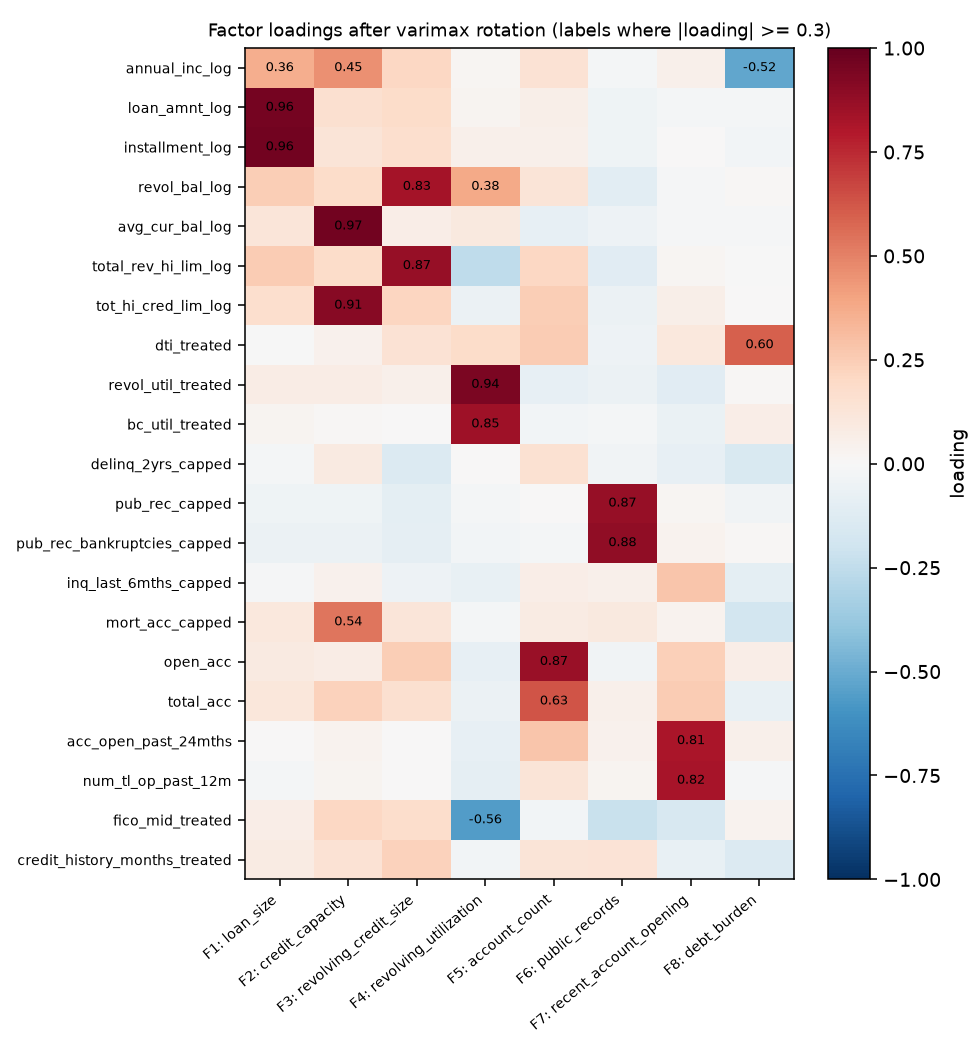

In [13]:
fm = FactorModel().fit(ds)                                       # fits on the fit window only, inside the class
L = fm.loadings_
shown = L.map(lambda v: "" if abs(v) < 0.3 else f"{v:+.2f}")
print(shown.to_string())
summary = pd.DataFrame({"share of total variance": pd.Series(fm.factor_variance_)}).T.round(3)
print("\nvariance explained by each factor:")
print(summary.to_string())
print(f"total: {sum(fm.factor_variance_.values()):.1%}")
display(Image("reports/a5_factor_analysis/figures/factor_loadings_varimax.png", width=860))

**Naming rule (in code, `src/credit_risk/factors.py`):** a factor receives a name only if it loads at 0.5 or more, on average, on the fields that name stands for; otherwise it stays unnamed. The names are not chosen by hand after looking.

In [14]:
rows = []
for name, fields in SIGNATURES.items():
    rows.append({"factor": name, "defined by": " + ".join(fields), "mean loading on those fields": float(L.loc[fields, name].abs().mean())})
print(pd.DataFrame(rows).round(2).to_string(index=False))
print(f"\nminimum mean loading required: {MIN_MEAN_LOADING}")

                factor                                   defined by  mean loading on those fields
       credit_capacity        avg_cur_bal_log + tot_hi_cred_lim_log                          0.94
             loan_size              installment_log + loan_amnt_log                          0.96
 revolving_credit_size         total_rev_hi_lim_log + revol_bal_log                          0.85
         account_count                         open_acc + total_acc                          0.75
 revolving_utilization         revol_util_treated + bc_util_treated                          0.89
        public_records pub_rec_capped + pub_rec_bankruptcies_capped                          0.88
recent_account_opening    num_tl_op_past_12m + acc_open_past_24mths                          0.82
           debt_burden                 dti_treated + annual_inc_log                          0.56

minimum mean loading required: 0.5


**Reading it, factor by factor** (names come only from what loads):

| Factor | What loads on it | Plain meaning |
|---|---|---|
| `credit_capacity` | average balance 0.97, total credit limit 0.91, mortgage accounts 0.54 | how much credit this person already carries |
| `loan_size` | installment 0.96, loan amount 0.96 | how large this loan is |
| `revolving_credit_size` | revolving limit 0.87, revolving balance 0.83 | size of card-type credit |
| `account_count` | open accounts 0.87, total accounts 0.63 | how many accounts |
| `revolving_utilization` | revolving utilisation 0.94, bank-card utilisation 0.85, FICO -0.56 | how stretched the cards are (a high-utilisation borrower tends to have a lower FICO) |
| `public_records` | bankruptcies 0.88, public records 0.87 | derogatory public records |
| `recent_account_opening` | accounts opened in 12 months 0.82, in 24 months 0.81 | borrowing a lot lately |
| `debt_burden` | `dti` 0.60, income -0.52 | debt relative to pay |

Together the eight factors explain about 68% of the variance. Income is the one field with a visible cross-loading (credit capacity 0.45, debt burden -0.52), which is natural: income is related to both.

### 3e. What the factors do not capture, and stability

In [15]:
comm = (L ** 2).sum(axis=1).sort_values()
print("fields least explained by the 8 factors (communality = share of the field the factors explain):")
print(comm.head(5).round(2).to_string())
print()
print("stability: congruence of loadings fitted on 2013 loans vs 2014 loans (1 = identical):")
print(pd.read_csv("reports/a5_factor_analysis/tables/stability_2013_vs_2014.csv").round(3).T.to_string(header=False))

fields least explained by the 8 factors (communality = share of the field the factors explain):
delinq_2yrs_capped               0.08
inq_last_6mths_capped            0.10
credit_history_months_treated    0.14
mort_acc_capped                  0.37
fico_mid_treated                 0.47

stability: congruence of loadings fitted on 2013 loans vs 2014 loans (1 = identical):
factor                      F1     F2     F3     F4     F5     F6     F7     F8
congruence_2013_vs_2014  0.999  0.997  0.996  0.997  0.989  0.999  0.996  0.993


**Reading it.** Four fields are barely represented: `delinq_2yrs` (communality 0.08), `inq_last_6mths` (0.10), credit history (0.14) and `mort_acc` (0.37). They are mostly their own noise, so they stay in the model as raw fields beside the factors, and this agrees with their low KMO. **The factors are stable:** loadings fitted separately on 2013 and 2014 loans match almost perfectly (congruence 0.989 to 0.999).

### 3f. Factor scores
Each loan gets a score on each factor. The scores stored in the contract are exactly what the fitted model produces:

In [16]:
scored = fm.transform(ds)
cols = [c for c in ds.columns if c.startswith("factor_")]
print("largest difference between the stored contract scores and a fresh transform:", float(np.abs(scored[cols].to_numpy() - ds[cols].to_numpy()).max()))

y = fit.defaulted.to_numpy()
auc = {c.replace("factor_", ""): max(roc_auc_score(y, fit[c]), 1 - roc_auc_score(y, fit[c])) for c in cols}
print("\nhow well each factor ranks defaulters on its own (AUC, 0.5 = no signal):")
print(pd.Series(auc).round(3).sort_values(ascending=False).to_string())
print("\nlargest correlation between two factor scores:", float(np.abs(np.corrcoef(fit[cols].T.to_numpy()) - np.eye(len(cols))).max().round(3)))

largest difference between the stored contract scores and a fresh transform: 0.0

how well each factor ranks defaulters on its own (AUC, 0.5 = no signal):
recent_account_opening    0.588
debt_burden               0.569
revolving_utilization     0.561
credit_capacity           0.559
loan_size                 0.546
revolving_credit_size     0.535
account_count             0.517
public_records            0.516

largest correlation between two factor scores: 0.08


**Reading it.** The stored scores match a fresh fit exactly (difference 0). Individually the factors are modest rankers (AUC about 0.52 to 0.59): most of the signal in credit data is spread across many weak fields. `recent_account_opening` and `debt_burden` do best; `public_records` and `account_count` are almost no signal on their own. Whether the factors add anything *beyond* the raw fields is tested in the model ablation (Part B), and notebook 06 compares them with the platform's grade.

## 4. When to prefer factor analysis over PCA (bullet 3, last sentence)

| | PCA | Factor analysis |
|---|---|---|
| What it summarises | all the variation, shared or not | only the variation fields **share** |
| A field that is mostly its own noise | gets a component of its own (as with the noise field in the simulated example) | is recognised through low communality |
| Interpretability | components can mix fields | factors can be named from their loadings |
| Best when | the goal is compression for a model | the goal is meaningful constructs that people must explain |

**For this problem factor analysis is the better choice for explanation.** Decisions must be explained to a credit officer and a declined customer, so "your revolving utilisation is high" is more useful than "your fifth component is low". Several fields (`delinq_2yrs`, `inq_last_6mths`) are mostly noise, which FA handles honestly. PCA stays in the contract as the compact alternative, and the Part B ablation reports which of raw fields, PCA scores and factor scores actually help.

## 5. Fitted on the fit window only, and stored in the contract

In [17]:
print("stored in data_spec.json:", len(spec["pca"]), "PCA components,", len(spec["factors"]), "factors")
print(f"first factor entry: {json.dumps(spec['factors'][0])}")
print("\ntests that guard the rule:")
print(*[f"  {l[4:-1]}" for l in Path("tests/test_factors.py").read_text().splitlines() if l.startswith("def test")], sep="\n")

stored in data_spec.json: 7 PCA components, 8 factors
first factor entry: {"name": "credit_capacity", "method": "factor_analysis_varimax", "top_loadings": {"avg_cur_bal_log": 0.968, "tot_hi_cred_lim_log": 0.913, "mort_acc_capped": 0.538}, "variance_explained": 0.1201}

tests that guard the rule:
  test_factors_are_named_from_their_loadings_with_a_stable_sign()
  test_a_factor_that_matches_no_signature_stays_unnamed()
  test_fit_ignores_2015_loans_and_scores_are_repeatable()
  test_spec_entries_are_json_ready()


## Summary: what the brief asked, and where it is answered

| Brief item | Answered in |
|---|---|
| Spearman matrix and VIF, and why reduce | section 1 |
| PCA on treated and standardised fields: variance, number of components with a reason, loadings | section 2 |
| How much outlier treatment changed the leading components | section 2 (last part) |
| KMO and Bartlett | section 3a |
| Number of factors (parallel analysis, stated rule) | section 3b |
| Rotation chosen and justified | section 3c |
| Names only from loadings, factor scores | sections 3d and 3f |
| When FA over PCA | section 4 |